# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170367         # <-- your full roll number
NAME = "Manvi Gajrani"          # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170367   Name: Manvi Gajrani   Fingerprint: 737684F7   Tickets: 14

Ticket_ID                                                                            Ticket_Text
      T01                       I tried restarting the lms since yesterday. It worked yesterday.
      T02                              The Wi-Fi has stopped syncing. Is there another solution?
      T03                                   The server has stopped syncing. It worked yesterday.
      T04                                                   Python 3.12 was installed yesterday.
      T05                                    The e-mail is showing an error. Can you check this?
      T06               Projector keeps disconnecting during the lab. Is there another solution?
      T07                 I cannot access the Matlab since yesterday. Is there another solution?
      T08                                                  The Wi-Fi works, but the VPN doesn't.
      T09               Server keeps askin

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
# Generate the official dataset
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)

print("Name:", NAME)
print("Roll Number:", ROLL_NO)
print("Dataset Fingerprint:", FINGERPRINT)
print("Focus Ticket IDs:", FOCUS)
print("Number of Tickets:", len(df))

print("\nGENERATED TICKETS")
print(df.to_string(index=False))

# Use the supplied process_ticket() and is_punct() functions without modification.
# Process every ticket with the official pipeline.
processed = [
    process_ticket(text)
    for text in df["Ticket_Text"]
]

# Preserve original ticket IDs and text
for i, result in enumerate(processed):
    result["Ticket_ID"] = df.iloc[i]["Ticket_ID"]
    result["Ticket_Text"] = df.iloc[i]["Ticket_Text"]

# Build the per-ticket statistics table
rows = []

for result in processed:
    rows.append({
        "Ticket_ID": result["Ticket_ID"],
        "Number of sentences": len(result["sentences"]),
        "Number of tokens": len(result["tokens"]),
        "Number of punctuation tokens": len(result["punct"]),
        "Number of stopwords": len(result["stops"]),
        "Number of unique tokens": len(set(result["tokens"])),
        "Number of final tokens": len(result["final"])
    })

preprocessing_df = pd.DataFrame(rows)

# Add TOTAL row
total_row = {
    "Ticket_ID": "TOTAL",
    "Number of sentences": preprocessing_df["Number of sentences"].sum(),
    "Number of tokens": preprocessing_df["Number of tokens"].sum(),
    "Number of punctuation tokens": preprocessing_df["Number of punctuation tokens"].sum(),
    "Number of stopwords": preprocessing_df["Number of stopwords"].sum(),
    "Number of unique tokens": len({
        token
        for result in processed
        for token in result["tokens"]
    }),
    "Number of final tokens": preprocessing_df["Number of final tokens"].sum()
}

preprocessing_df = pd.concat(
    [preprocessing_df, pd.DataFrame([total_row])],
    ignore_index=True
)

print(preprocessing_df.to_string(index=False))

# Required detailed evidence for one selected ticket.
selected_id = FOCUS[0]
selected = next(result for result in processed if result["Ticket_ID"] == selected_id)
print(f"\nDETAIL FOR {selected_id}: {selected['Ticket_Text']}")
for label, key in [("Tokens", "tokens"), ("Punctuation tokens", "punct"),
                   ("Stopwords", "stops"), ("Final tokens", "final")]:
    print(f"{label}: {selected[key]}")

Name: Manvi Gajrani
Roll Number: 1024170367
Dataset Fingerprint: 737684F7
Focus Ticket IDs: ['T13', 'T14']
Number of Tickets: 14

GENERATED TICKETS
Ticket_ID                                                                            Ticket_Text
      T01                       I tried restarting the lms since yesterday. It worked yesterday.
      T02                              The Wi-Fi has stopped syncing. Is there another solution?
      T03                                   The server has stopped syncing. It worked yesterday.
      T04                                                   Python 3.12 was installed yesterday.
      T05                                    The e-mail is showing an error. Can you check this?
      T06               Projector keeps disconnecting during the lab. Is there another solution?
      T07                 I cannot access the Matlab since yesterday. Is there another solution?
      T08                                                  The Wi-Fi works, 

In [ ]:

rows = []

for result in processed:
    rows.append({
        "Ticket_ID": result["Ticket_ID"],
        "Number of sentences": len(result["sentences"]),
        "Number of tokens": len(result["tokens"]),
        "Number of punctuation tokens": len(result["punct"]),
        "Number of stopwords": len(result["stops"]),
        "Number of unique tokens": len(set(result["tokens"])),
        "Number of final tokens": len(result["final"])
    })

preprocessing_df = pd.DataFrame(rows)

total_row = {
    "Ticket_ID": "TOTAL",
    "Number of sentences": preprocessing_df["Number of sentences"].sum(),
    "Number of tokens": preprocessing_df["Number of tokens"].sum(),
    "Number of punctuation tokens": preprocessing_df["Number of punctuation tokens"].sum(),
    "Number of stopwords": preprocessing_df["Number of stopwords"].sum(),
    "Number of unique tokens": len(set(
        token
        for result in processed
        for token in result["tokens"]
    )),
    "Number of final tokens": preprocessing_df["Number of final tokens"].sum()
}

preprocessing_df = pd.concat(
    [preprocessing_df, pd.DataFrame([total_row])],
    ignore_index=True
)

print(preprocessing_df.to_string(index=False))


Ticket_ID  Number of sentences  Number of tokens  Number of punctuation tokens  Number of stopwords  Number of unique tokens  Number of final tokens
      T01                    2                12                             2                    3                       10                       7
      T02                    2                11                             2                    4                       11                       5
      T03                    2                10                             2                    3                        9                       5
      T04                    1                 6                             1                    1                        6                       4
      T05                    2                12                             2                    6                       12                       4
      T06                    2                12                             2                    4       

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*Some final tokens, such as `n't`, `'s`, and `ca`, are not complete words. They come from contractions such as “don't”, “it's”, and “can't”. NLTK's word tokenizer splits contractions into separate tokens, and the stopword-removal step may retain these fragments because they are not always recognized as stopwords individually.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
import re

# Patterns for extraction
long_word_pattern = r"\b[A-Za-z]{6,}\b"
number_pattern = r"(?<!\w)\d+(?:,\d{3})*(?:\.\d+)+(?!\w)|(?<!\w)\d{1,3}(?:,\d{3})+(?!\w)|(?<!\w)\d+(?!\w)"
capitalized_pattern = r"\b[A-Z][a-zA-Z]*\b"
vowel_pattern = r"\b[AEIOUaeiou][A-Za-z]*\b"

def analyze_regex(text):
    return {
        "Long words (>5 letters)": re.findall(long_word_pattern, text),
        "Numbers": re.findall(number_pattern, text),
        "Capitalized words": re.findall(capitalized_pattern, text),
        "Words starting with vowel": re.findall(vowel_pattern, text)
    }

# Extract information from all raw tickets
for _, row in df.iterrows():
    print("\nTicket:", row["Ticket_ID"])
    print("Text:", row["Ticket_Text"])

    result = analyze_regex(row["Ticket_Text"])

    for category, values in result.items():
        print(category + ":", values)

# Test the same patterns on the provided test lines
print("\n--- TEST LINES ---")

for line in TEST_LINES:
    print("\nText:", line)

    for category, values in analyze_regex(line).items():
        print(category + ":", values)

# Replace emails, URLs and phone numbers
def redact_sensitive_info(text):
    text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "<EMAIL>",
        text
    )

    text = re.sub(
        r"(?:https?://|www\.)[A-Za-z0-9.-]+\.[A-Za-z]{2,}(?:/[A-Za-z0-9._~:/?#[\]@!$&'()*+,;=%-]*[A-Za-z0-9/#])?",
        "<URL>",
        text,
        flags=re.IGNORECASE
    )

    text = re.sub(
        r"(?<!\w)(?:\+\d{1,3}[-\s]?\d{5}[-\s]?\d{5}|\d{4}-\d{3}-\d{4})(?!\w)",
        "<PHONE>",
        text
    )

    return text

print("\n--- REDACTED TICKETS ---")

for _, row in df.iterrows():
    print(row["Ticket_ID"], ":", redact_sensitive_info(row["Ticket_Text"]))

print("\n--- REDACTED TEST LINES ---")

for line in TEST_LINES:
    print(redact_sensitive_info(line))


Ticket: T01
Text: I tried restarting the lms since yesterday. It worked yesterday.
Long words (>5 letters): ['restarting', 'yesterday', 'worked', 'yesterday']
Numbers: []
Capitalized words: ['I', 'It']
Words starting with vowel: ['I', 'It']

Ticket: T02
Text: The Wi-Fi has stopped syncing. Is there another solution?
Long words (>5 letters): ['stopped', 'syncing', 'another', 'solution']
Numbers: []
Capitalized words: ['The', 'Wi', 'Fi', 'Is']
Words starting with vowel: ['Is', 'another']

Ticket: T03
Text: The server has stopped syncing. It worked yesterday.
Long words (>5 letters): ['server', 'stopped', 'syncing', 'worked', 'yesterday']
Numbers: []
Capitalized words: ['The', 'It']
Words starting with vowel: ['It']

Ticket: T04
Text: Python 3.12 was installed yesterday.
Long words (>5 letters): ['Python', 'installed', 'yesterday']
Numbers: ['3.12']
Capitalized words: ['Python']
Words starting with vowel: ['installed']

Ticket: T05
Text: The e-mail is showing an error. Can you check this

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
# Your code
# Your code
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = (
    r"(?:https?://|www\.)[A-Za-z0-9.-]+\.[A-Za-z]{2,}(?:/[A-Za-z0-9._~:/?#[\]@!$&'()*+,;=%-]*[A-Za-z0-9/#])?"
    r"|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
    r"|\+\d{1,3}[-\s]?\d{5}[-\s]?\d{5}|\d{4}-\d{3}-\d{4}"
    r"|\d+(?:\.\d+)+"
    r"|[A-Za-z0-9]+(?:['\u2019][A-Za-z]+)*(?:-[A-Za-z0-9]+(?:['\u2019][A-Za-z]+)*)*"
    r"|[^\w\s]"
)

my_tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    """Tokenize text while preserving the required multi-character forms."""
    return my_tokenizer.tokenize(text)

# Compare tokenization of the test lines
print("--- TEST LINES ---")

for line in TEST_LINES:
    print("\nText:", line)
    print("word_tokenize:", word_tokenize(line))
    print("my_tokenize:", my_tokenize(line))

# Compare tokenization of every ticket
different_tickets = []

for _, row in df.iterrows():
    text = row["Ticket_Text"]

    standard_tokens = word_tokenize(text)
    custom_tokens = my_tokenize(text)

    if standard_tokens != custom_tokens:
        different_tickets.append(row["Ticket_ID"])

    print("\nTicket:", row["Ticket_ID"])
    print("Standard:", standard_tokens)
    print("Custom:  ", custom_tokens)

print(
    "\nNumber of tickets tokenized differently:",
    len(different_tickets)
)
print("Different ticket IDs:", different_tickets)

--- TEST LINES ---

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
my_tokenize: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* **2 tickets** differ: *Six tickets (T07, T08, T10, T11, T12 and T13) are tokenized differently by `my_tokenize()` and `word_tokenize()`.

Three clear differences are:

1. Contractions:`word_tokenize("doesn't")` returns `['does', "n't"]`, while the custom tokenizer keeps `doesn't` as one token.
2. Emails and URLs:`word_tokenize()` splits email addresses and URLs into multiple tokens, whereas the custom tokenizer preserves each complete email address and URL as a single token.
3. Hyphenated and contracted forms: The custom tokenizer preserves forms such as `Rao's` as one token and treats `cannot` as one token, whereas `word_tokenize()` splits these differently.

The custom tokenizer is designed to preserve the specified multi-character patterns, while the standard tokenizer follows its own tokenization rules.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
# Your code
# Your code
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

porter = PorterStemmer()
lancaster = LancasterStemmer()

# Custom suffix-based stemmer
regex_stemmer = RegexpStemmer(
    r"(?:ing|ed|s)$",
    min=3
)

lemmatizer = WordNetLemmatizer()

# Convert POS tags from NLTK to WordNet POS tags
def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

# Collect unique final tokens from Q1
unique_tokens = sorted({
    token
    for result in processed
    for token in result["final"]
})

# Get POS tags
tagged_tokens = pos_tag(unique_tokens)

rows = []

for word, tag in tagged_tokens:
    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regex_result = regex_stemmer.stem(word)

    wn_pos = get_wordnet_pos(tag)
    lemma_result = lemmatizer.lemmatize(word, pos=wn_pos)

    # Keep words where at least one method gives a different result
    if len({
        porter_result,
        lancaster_result,
        regex_result,
        lemma_result
    }) > 1:
        rows.append({
            "Word": word,
            "POS": tag,
            "Porter": porter_result,
            "Lancaster": lancaster_result,
            "RegexStemmer": regex_result,
            "WordNet Lemma": lemma_result
        })

comparison_df = pd.DataFrame(rows)

print("Number of unique final tokens:", len(unique_tokens))
print("\nWords with differing outputs:")
print(comparison_df.to_string(index=False))

Number of unique final tokens: 57

Words with differing outputs:
     Word POS    Porter Lancaster RegexStemmer WordNet Lemma
   access  NN    access    access        acces        access
  another  DT     anoth     anoth      another       another
  changed VBD     chang     chang        chang        change
    error  NN     error        er        error         error
installed VBD    instal    instal      install        instal
   latest JJS    latest    latest       latest          late
      lms  NN        lm       lms           lm            lm
   mobile VBP     mobil      mobl       mobile        mobile
   occurs  JJ     occur       occ        occur        occurs
   portal  NN    portal      port       portal        portal
projector  NN projector   project    projector     projector
   server  NN    server      serv       server        server
    since  IN      sinc      sint        since         since
 solution  NN     solut      solv     solution      solution
  stopped VBD      s

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* I chose the suffix rule `(?:ing|ed|s)$` because my final tokens include `syncing`, `disconnecting`, `stopped`, `occurs` and `keeps`; each has one of these endings. An over-stemming example is Lancaster `server → serv` (and `open → op`), which removes meaningful material. An under-stemming example is that the simple RegexpStemmer gives `tried → tri` but leaves the related form `try` unchanged; it does not reliably normalize the two forms to the same meaningful base. POS-aware WordNet lemmatization instead gives `tried → try` when tagged as a verb.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS
             Corpus  Total tokens  Unique tokens    TTR
    S1 - All tokens           168             91 0.5417
S2 - No punctuation           139             85 0.6115
  S3 - Final tokens            81             57 0.7037
S4 - Porter stemmed            81             55 0.6790

TOP 10 WORDS IN S1
[('.', 21), ('the', 12), ('yesterday', 8), ('is', 6), ('i', 5), ('?', 4), ('it', 3), ('worked', 3), ('there', 3), ('another', 3)]

TOP 10 WORDS IN S3
[('yesterday', 8), ('worked', 3), ('another', 3), ('solution', 3), ("n't", 3), ('since', 2), ('wi-fi', 2), ('stopped', 2), ('syncing', 2), ('server', 2)]


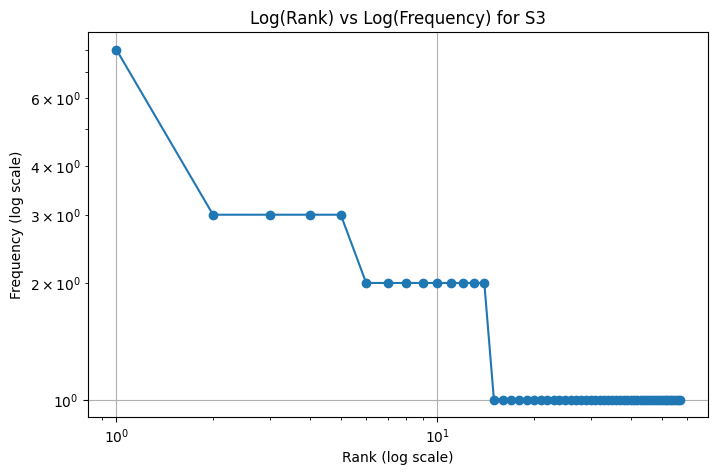


TOP 5 BIGRAMS IN S1
[(('yesterday', '.'), 7), (('.', 'the'), 4), (('.', 'it'), 3), (('it', 'worked'), 3), (('worked', 'yesterday'), 3)]

TOP 5 BIGRAMS IN S3
[(('worked', 'yesterday'), 3), (('another', 'solution'), 3), (('since', 'yesterday'), 2), (('stopped', 'syncing'), 2), (('working', 'yesterday'), 2)]


In [ ]:
# Your code
# Your code

from collections import Counter
from nltk.util import bigrams
from nltk.stem import PorterStemmer
import matplotlib.pyplot as plt
import math

# S1: All tokens, including punctuation
S1 = [
    token.lower()
    for text in df["Ticket_Text"]
    for token in word_tokenize(text)
]

# S2: All tokens except punctuation
S2 = [token for token in S1 if not is_punct(token)]

# S3: Final tokens after the Q1 preprocessing pipeline
S3 = [
    token
    for result in processed
    for token in result["final"]
]

# S4: S3 after Porter stemming
porter = PorterStemmer()
S4 = [porter.stem(token) for token in S3]

# Calculate corpus statistics
def corpus_stats(name, tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0

    return {
        "Corpus": name,
        "Total tokens": total,
        "Unique tokens": unique,
        "TTR": round(ttr, 4)
    }

stats_df = pd.DataFrame([
    corpus_stats("S1 - All tokens", S1),
    corpus_stats("S2 - No punctuation", S2),
    corpus_stats("S3 - Final tokens", S3),
    corpus_stats("S4 - Porter stemmed", S4)
])

print("CORPUS STATISTICS")
print(stats_df.to_string(index=False))

# Top 10 words in S1 and S3
print("\nTOP 10 WORDS IN S1")
print(Counter(S1).most_common(10))

print("\nTOP 10 WORDS IN S3")
print(Counter(S3).most_common(10))

# Log(rank) vs log(frequency) plot for S3
frequency = Counter(S3).most_common()
ranks = list(range(1, len(frequency) + 1))
frequencies = [count for word, count in frequency]

plt.figure(figsize=(8, 5))
plt.loglog(ranks, frequencies, marker="o", linestyle="-")
plt.xlabel("Rank (log scale)")
plt.ylabel("Frequency (log scale)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()

# Top 5 bigrams in S1 and S3
print("\nTOP 5 BIGRAMS IN S1")
print(Counter(bigrams(S1)).most_common(5))

print("\nTOP 5 BIGRAMS IN S3")
print(Counter(bigrams(S3)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* In my dataset, TTR increases from 0.5417 in S1 to 0.6115 in S2 and 0.7037 in S3. Removing punctuation and stopwords reduces the total number of tokens, including many frequent tokens, so the proportion of unique tokens increases. After Porter stemming, TTR decreases to 0.6790 in S4 because the number of unique tokens falls from 57 to 55, while the total token count remains 81. Stemming combines some different word forms into the same stem.

**(a) Why does TTR change from S1 to S4?**

TTR increases from 0.5417 in S1 to 0.7037 in S3 because punctuation and stopwords are removed, reducing the total token count. It then decreases to 0.6790 in S4 because Porter stemming merges some distinct word forms, reducing the number of unique tokens from 57 to 55 while the total remains 81.

**(b) Give one example where `word_tokenize()` and your tokenizer differ.**

For `doesn't`, `word_tokenize()` returns `['does', "n't"]`, whereas `my_tokenize()` returns `["doesn't"]`. The custom tokenizer preserves contractions as single tokens.

**(c) Give one example where stemming produces an undesirable result.**

Lancaster stemming changes `server` to `serv`. This aggressive reduction removes meaningful letters and produces a less interpretable stem.

**(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.**

The word `changed` is tagged as a past-tense verb (`VBD`). WordNet lemmatization returns `change`, its dictionary base form, whereas Porter stemming returns `chang`. The lemma preserves the recognizable word form and its meaning more clearly.